# The idea

Stochastic imputation is a tool worth considering when the downstream task depends on preserving variation, and entrywise RMSE alone cannot tell you which imputation serves that task best.

In [281]:
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

# Synthetic data generation

In [199]:
seed = 42
rng = np.random.default_rng(seed)

Equicorrelation - unit variances and all other entries are equal $\rho$.
$$
\Sigma = (1 - \rho)\mathbf{I}_d + \rho\mathbf{1}\mathbf{1}^T
$$
Positive definitness requires
$$
-\frac{1}{d-1} < \rho < 1
$$

In [200]:
# synthetic data generation
# generated matrix is n x d
n = 1000
d = 2

# d x 1 vector of zero means
mu = np.zeros(d)

I_d = np.eye(d)
rho = 0.8
# positive definitness condition
assert (-1/(d-1) < rho) and (rho < 1)

# equicorrelation Sigma has unit variances
Sigma = (1 - rho) * I_d + rho * np.ones((d, 1)) @ np.ones((d, 1)).T
# unit variances sanity check
# the formula should deliver unit variances
assert np.allclose(np.diag(Sigma), np.ones(d))

Sigma = np.array([
    [1.0, 0.3],
    [0.3, 1.2],
])

X = rng.multivariate_normal(
    mu,
    Sigma,
    size=n
)

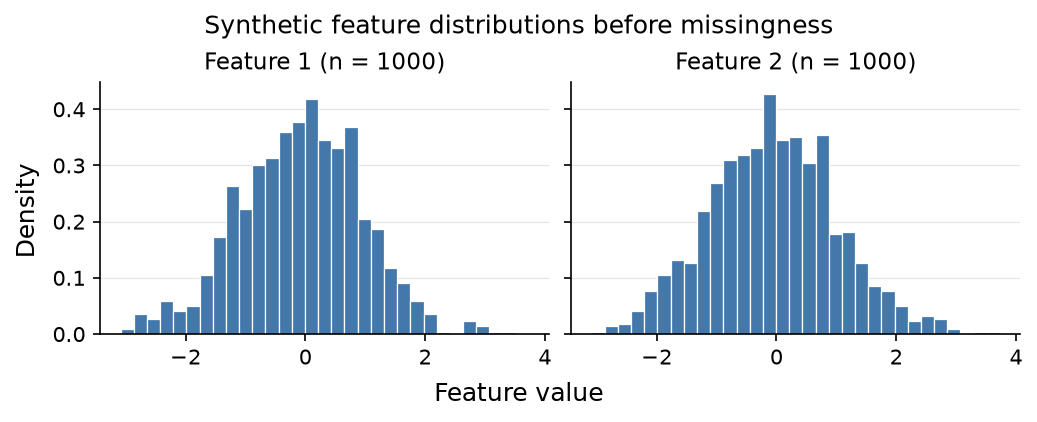

In [201]:
# Faceted histograms: common bins and axes support feature comparisons.
feature_names = [f"Feature {k + 1}" for k in range(X.shape[1])]
histogram_bins = np.histogram_bin_edges(X.ravel(), bins="fd")
plot_style = {
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}

with plt.rc_context(plot_style):
    ncols = min(3, X.shape[1])
    nrows = (X.shape[1] + ncols - 1) // ncols
    fig_histograms, axes = plt.subplots(
        nrows, ncols, figsize=(3.4 * ncols, 2.7 * nrows),
        sharex=True, sharey=True, squeeze=False, layout="constrained",
    )
    for k, ax in enumerate(axes.flat):
        if k >= X.shape[1]:
            ax.set_visible(False)
            continue
        ax.hist(
            X[:, k], bins=histogram_bins, density=True,
            color="#4477AA", edgecolor="white", linewidth=0.6,
        )
        ax.set_title(f"{feature_names[k]} (n = {X.shape[0]})")
        ax.set_axisbelow(True)
        ax.grid(axis="y", color="0.9", linewidth=0.6)
    fig_histograms.supxlabel("Feature value")
    fig_histograms.supylabel("Density")
    fig_histograms.suptitle("Synthetic feature distributions before missingness")
    plt.show()

# Applying missingness

Histograms above use the complete synthetic data, with shared Freedman–Diaconis
bins calculated from the pooled values and common axes. Each histogram has unit
area (density), allowing direct comparisons between features.

The next cell selects a fixed number of rows uniformly at random, independently
of their values, and removes the last feature in those rows. Thus `p` is the
missing fraction of the selected feature, not of the entire matrix. This is an
MCAR construction with a fixed missing count, rather than independent Bernoulli
masking of every entry.

In [202]:
# the probability of a value being missing
p = 0.3
# missingness is applied to the last column
miss_col = d - 1

In [203]:
X_mcar = X.copy()
# choose missing indices
missing_idx = rng.choice(n, size=round(n*p), replace=False, shuffle=False)
# apply missingness
X_mcar[missing_idx, miss_col] = np.nan

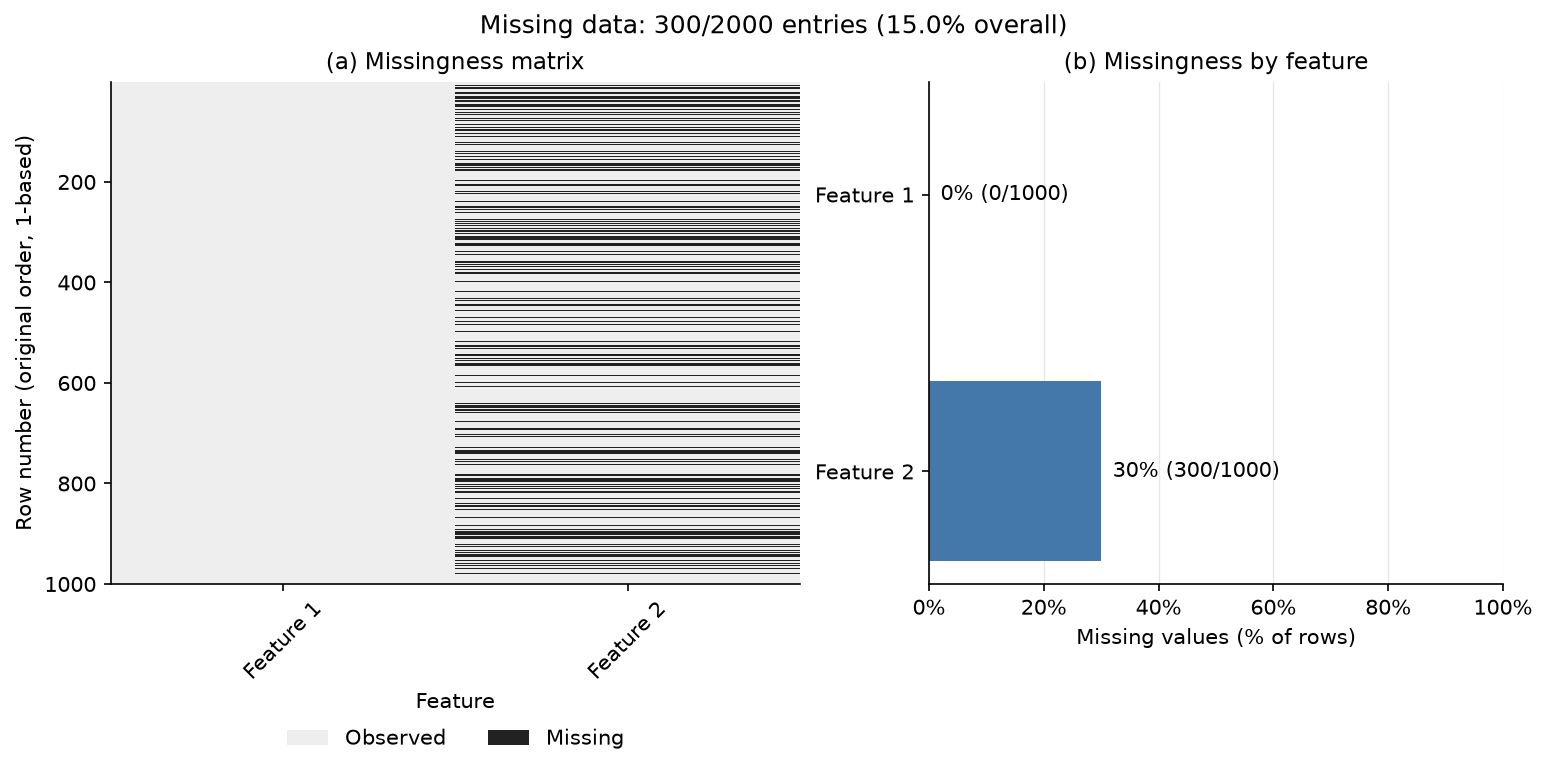

In [204]:
# Show both the locations and the marginal proportions of missing values.
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

missing_mask = np.isnan(X_mcar)
missing_counts = missing_mask.sum(axis=0)
missing_fractions = missing_mask.mean(axis=0)
missing_colors = ["#EEEEEE", "#222222"]  # Grayscale remains legible in print.
missing_cmap = ListedColormap(missing_colors)
missing_norm = BoundaryNorm([-0.5, 0.5, 1.5], missing_cmap.N)

with plt.rc_context(plot_style):
    fig_missingness, (ax_matrix, ax_bars) = plt.subplots(
        1, 2, figsize=(10.2, 5.0), gridspec_kw={"width_ratios": [1.2, 1]},
        layout="constrained",
    )
    ax_matrix.imshow(
        missing_mask, cmap=missing_cmap, norm=missing_norm,
        aspect="auto", interpolation="nearest", origin="upper",
        extent=(0.5, X_mcar.shape[1] + 0.5, X_mcar.shape[0] + 0.5, 0.5),
    )
    ax_matrix.set_xticks(np.arange(1, X_mcar.shape[1] + 1), feature_names)
    ax_matrix.tick_params(axis="x", labelrotation=45)
    ax_matrix.set_xlabel("Feature")
    ax_matrix.set_ylabel("Row number (original order, 1-based)")
    ax_matrix.set_title("(a) Missingness matrix")
    ax_matrix.legend(
        handles=[Patch(facecolor=c, label=label) for c, label in
                 zip(missing_colors, ["Observed", "Missing"])],
        loc="upper center", bbox_to_anchor=(0.5, -0.25),
        ncol=2, frameon=False,
    )

    positions = np.arange(X_mcar.shape[1])
    ax_bars.barh(positions, missing_fractions, color="#4477AA", height=0.65)
    ax_bars.set_yticks(positions, feature_names)
    ax_bars.invert_yaxis()
    ax_bars.set_xlim(0, 1)
    ax_bars.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax_bars.set_xlabel("Missing values (% of rows)")
    ax_bars.set_title("(b) Missingness by feature")
    ax_bars.set_axisbelow(True)
    ax_bars.grid(axis="x", color="0.9", linewidth=0.6)
    for position, fraction, count in zip(positions, missing_fractions, missing_counts):
        ax_bars.text(
            min(fraction + 0.02, 0.98), position,
            f"{fraction:.0%} ({count}/{X_mcar.shape[0]})",
            ha="left" if fraction < 0.8 else "right", va="center",
        )
    fig_missingness.suptitle(
        f"Missing data: {missing_mask.sum()}/{missing_mask.size} entries "
        f"({missing_mask.mean():.1%} overall)"
    )
    plt.show()

The binary matrix preserves the original row and feature order; the bars report
missing fractions and counts, including fully observed features. These plots
summarize where values are absent; they cannot establish MCAR from observed data
alone. Here MCAR follows from the synthetic masking mechanism.

These are conventional distribution and missing-data views; see the
[Seaborn distribution guide](https://seaborn.pydata.org/tutorial/distributions.html)
and Tierney & Cook (2023),
["Expanding Tidy Data Principles to Facilitate Missing Data Exploration, Visualization and Assessment of Imputations"](https://doi.org/10.18637/jss.v105.i07).

# Imputation

In [205]:
def RMSE(X_true, X_imp):
    if X_true.shape != X_imp.shape:
        raise ValueError(f"Comparing true matrix of shape {X_true.shape} with imputed matrix of shape {X_imp.shape}.")
    return np.sqrt(np.mean((X_true - X_imp)**2))

In [206]:
missing_mask = np.isnan(X_mcar[:, miss_col])

## Unconditional mean

In [207]:
ucond_mean = X_mcar[~missing_mask, miss_col].mean()
X_imp_ucond_mean = X_mcar.copy()
X_imp_ucond_mean[missing_mask, miss_col] = ucond_mean
assert np.isnan(X_imp_ucond_mean).sum() == 0

## Conditional mean

In [208]:
def nancov(X: np.ndarray):
    row_nan_mask = np.isnan(X).any(axis=1)
    return np.cov(X[~row_nan_mask], rowvar=False)

In [209]:
def coord_cond_distr(
    Y: np.ndarray,
    mus: np.ndarray,
    Sigma: np.ndarray
):
    """
    Calculates the conditional distribution
    of missing coordinated given the existing coordinate values
    
    Y: m x d matrix with missingness,
        observations are in rows,
        each row has to follow the same missingness pattern
    mus: (d, ) or (d, 1) vector of means
    Sigma: (d, d) covariance matrix
    """
    if Y.size == 0:
        raise ValueError("Empty input matrix Y provided.")

    # mask checking if Y is a vector
    is_vector = Y.ndim == 1 or (Y.ndim == 2 and 1 in Y.shape)
        
    # choose missing coordinate indices
    nan_mask = np.isnan(Y)
    
    # all observations must have a consistent missingness pattern
    # if more than one observation provided
    if (
        not is_vector
        # and Y has a consistent missingness pattern across rows
        # broadcast comparison of the first row against all rows
        and not np.all(nan_mask == nan_mask[0])
    ):
        raise ValueError("Inconsistent missingness pattern in the input matrix.")

    # the mask ultimately chooses a vector coordinates,
    # it is a per observation missing mask
    if not is_vector:
        nan_mask = nan_mask[0]

    # make mask's shape consistent (d,)
    nan_mask = nan_mask.ravel()

    if not nan_mask.any():
        raise ValueError("No missing values to estimate.")

    if nan_mask.all():
        raise ValueError("No observed values to condition on.")

    mus = mus.ravel()
    # recover dimension of a observation
    d = mus.size

    if d == 1:
        raise ValueError("Conditioning existing values looses meaning for d == 1.")

    I_d = np.eye(d)
    # existing values selector matrix
    A = I_d[~nan_mask]
    # missing values selector matrix
    B = I_d[nan_mask]

    mu_A = A @ mus
    mu_B = B @ mus

    Sigma_AA = A @ Sigma @ A.T
    Sigma_AB = A @ Sigma @ B.T
    Sigma_BA = Sigma_AB.T
    Sigma_BB = B @ Sigma @ B.T
    
    K = np.linalg.solve(Sigma_AA.T, Sigma_BA.T).T

    if is_vector:
        Y_obs = Y.ravel()[~nan_mask]
    else:
        Y_obs = Y[:, ~nan_mask]

    mu_cond = mu_B + (Y_obs - mu_A) @ K.T
    Sigma_cond = Sigma_BB - K@Sigma_AB

    return mu_cond, Sigma_cond

In [210]:
X_imp_cond_mean = X_mcar.copy()

imp_vals, cond_Sigma = coord_cond_distr(
    X_mcar[missing_mask],
    np.nanmean(X_mcar, axis=0),
    nancov(X_mcar))

X_imp_cond_mean[missing_mask, miss_col] = imp_vals.ravel()

## Stochastic imputation

In [211]:
X_imp_stochastic = X_mcar.copy()
missing_rows = np.flatnonzero(missing_mask)

for mu_cond, miss_row in zip(imp_vals, missing_rows, strict=True):
    draw = rng.multivariate_normal(mu_cond, cond_Sigma)
    X_imp_stochastic[miss_row, miss_col] = draw[0]

# Analysis

In [212]:
RMSE(X[missing_mask, miss_col], X_imp_ucond_mean[missing_mask, miss_col])

np.float64(1.0615021204586483)

In [213]:
RMSE(X[missing_mask, miss_col], X_imp_cond_mean[missing_mask, miss_col])

np.float64(1.0213018788316752)

In [214]:
RMSE(X[missing_mask, miss_col], X_imp_stochastic[missing_mask, miss_col])

np.float64(1.527039897806593)

In [227]:
cond_Sigma

array([[1.05388001]])

In [228]:
mu = X_imp_cond_mean[missing_mask, miss_col]
draws = X_imp_stochastic[missing_mask, miss_col]
noise = draws - mu

print(noise.mean())          # expected: 0
print(np.mean(noise**2))     # expected: 0.54

-0.0035297603836959074
1.1985841214179511


In [217]:
def eigendecomposition(X: np.ndarray):
    Sigma_X = nancov(X)
    return np.linalg.eigh(Sigma_X)

In [218]:
def angle_vec(v1, v2):
    alignment = abs(v1 @ v2)
    return np.degrees(np.arccos(np.clip(alignment, 0, 1)))

In [219]:
def angle_PCA1(X, Y):
    _, evec_X = eigendecomposition(X)
    _, evec_Y = eigendecomposition(Y)
    return angle_vec(evec_X[:, -1], evec_Y[:, -1])

In [220]:
def angle_true_sample_PCA1(Sigma, X):
    _, evec_true = np.linalg.eigh(Sigma)
    _, evec_sample = eigendecomposition(X)
    return angle_vec(evec_true[:, -1], evec_sample[:, -1])

In [221]:
_, evec_true = np.linalg.eigh(Sigma)
_, evec_sample = np.linalg.eigh(np.cov(X, rowvar=False))
angle_vec(evec_true[:, -1], evec_sample[:, -1])

np.float64(5.781985921048013)

In [222]:
print(angle_true_sample_PCA1(Sigma, X_imp_ucond_mean))
print(angle_PCA1(X, X_imp_ucond_mean))

25.926416695498833
20.144430774450797


In [223]:
print(angle_true_sample_PCA1(Sigma, X_imp_cond_mean))
print(angle_PCA1(X, X_imp_cond_mean))

19.755529080090895
13.973543159042832


In [224]:
print(angle_true_sample_PCA1(Sigma, X_imp_stochastic))
print(angle_PCA1(X, X_imp_stochastic))

3.6322377162954123
2.1497482047526133


In [226]:
evals, _ = eigendecomposition(X_imp_stochastic)

# The experiment

## The predictors
Three production process conditions.
- $Z_{\cdot 1}$ thermal conditions,
- $Z_{\cdot 2}$ mechanical conditions,
- $Z_{\cdot 3}$ chemical conditions.
$$ 
Z_i =
\begin{bmatrix}
Z_{i1} \\
Z_{i2} \\
Z_{i3}
\end{bmatrix}
\sim
\mathcal{N}_3\left(0, I_3\right)
$$

Each condition has mean 0 and variance 1 and they are independent.

Each i is one measurement occasion / time. Occasions are independent. There is no time dependence in this simulation, even if a factory might collect such measurements over time.

In [231]:
no_cond = 3
mus_Z = np.zeros(no_cond)
Sigma_Z = np.eye(no_cond)

no_measurements = 1000

Z = rng.multivariate_normal(mus_Z, Sigma_Z, no_measurements)

Each group contributes signal strength of 60, 25 and 15 respectively.
$$ L \in \mathbb{R}^{20\times 3} $$
Each row in L corresponds to a measured feature, each column corresponds to a condition.

In [247]:
groups = np.arange(no_cond)
signal_strength = [60, 25, 15]
no_features = 20
no_features_per_group = [10, 6, 4]
assert no_features == sum(no_features_per_group)
loadings = [np.sqrt(b[1]/b[0]) for b in zip(no_features_per_group, signal_strength)]

In [258]:
feature_groups = np.repeat(groups, no_features_per_group)
feature_groups

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2])

In [257]:
np.asarray(loadings)[feature_groups]

array([2.44948974, 2.44948974, 2.44948974, 2.44948974, 2.44948974,
       2.44948974, 2.44948974, 2.44948974, 2.44948974, 2.44948974,
       2.04124145, 2.04124145, 2.04124145, 2.04124145, 2.04124145,
       2.04124145, 1.93649167, 1.93649167, 1.93649167, 1.93649167])

In [262]:
L = np.zeros((no_features, no_cond))
L[np.arange(no_features), feature_groups] = np.asarray(loadings)[feature_groups]

In [266]:
var_epsilon = 0.1
mu_epsilon = 0
Epsilon = rng.normal(mu_epsilon, np.sqrt(var_epsilon), (no_measurements, no_features))

In [269]:
# the full observation matrix
X = Z @ L.T + Epsilon

In [270]:
Sigma_X_sample = np.cov(X, rowvar=False)

In [274]:
eigval_Sigma_X_sample, eigvec_Sigma_X_sample = np.linalg.eigh(Sigma_X_sample)
eigval_Sigma_X_sample

array([ 0.0765112 ,  0.08010283,  0.08273574,  0.08537737,  0.08939007,
        0.09243479,  0.09676989,  0.09789757,  0.0980452 ,  0.10062243,
        0.10484359,  0.10857425,  0.10998594,  0.11466518,  0.11506322,
        0.12394714,  0.1265329 , 15.47297763, 27.0943189 , 62.01914176])

## The response

In [278]:
var_eta = 0.25
mu_eta = 0
# response noise
Eta = rng.normal(mu_eta, np.sqrt(var_eta), no_measurements)

In [275]:
true_coeffs = np.array([0.1, 0.1, 1])

In [280]:
response = Z @ true_coeffs + Eta

## Divide into training and test sets

In [282]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    response,
    test_size=0.2,
    random_state=seed,
)

## Apply missingness to the training set
